# Attendance Anomaly Detection


In [1]:
import os
import sys
from pathlib import Path

# Add project root to path
sys.path.insert(0, os.path.abspath('..'))

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import joblib
import json

from sklearn.ensemble import IsolationForest
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline
from sklearn.metrics import precision_score


In [ ]:
# load data and features
data_path = '../data/raw/02_CortexHR_AI_ML_Dataset.xlsx'
df = pd.read_excel(data_path, sheet_name="attendance_monthly_features")

feature_columns = [
    "scheduled_days",
    "present_days",
    "wfh_days",
    "half_days_unpaid",
    "paid_leave_days",
    "unpaid_absence_days",
    "longest_unpaid_streak_days",
    "late_arrivals",
    "avg_hours_worked",
    "overtime_hours",
    "attendance_rate",
]

for col in feature_columns:
    df[col] = pd.to_numeric(df[col], errors="coerce")

print(f"Total attendance records: {len(df)}")
df[feature_columns].head()


Total attendance records: 7339


,scheduled_days,present_days,wfh_days,half_days_unpaid,paid_leave_days,unpaid_absence_days,longest_unpaid_streak_days,late_arrivals,avg_hours_worked,overtime_hours,attendance_rate
0,20,20,18,0,0,0,0,1,8.50,0.0,1.0000
1,21,20,18,1,0,0,0,2,8.71,0.0,0.9762
2,21,19,18,1,1,0,0,1,8.25,0.0,0.9286
3,23,23,22,0,0,0,0,1,8.63,0.0,1.0000
4,19,19,19,0,0,0,0,1,8.62,0.0,1.0000


In [ ]:
# Inject known anomalies
SEED = 42
rng = np.random.default_rng(SEED)

df["injected_anomaly"] = 0
df["injection_type"] = "normal"

number_to_inject = max(1, int(len(df) * 0.01))  # ~1% per type
available = list(range(len(df)))

# 1. Impossible hours
hours_idx = rng.choice(available, number_to_inject, replace=False).tolist()
available = [i for i in available if i not in hours_idx]

# 2. Long absences
absence_idx = rng.choice(available, number_to_inject, replace=False).tolist()
available = [i for i in available if i not in absence_idx]

# 3. Pattern changes
pattern_idx = rng.choice(available, number_to_inject, replace=False).tolist()

for i in hours_idx:
    df.loc[i, "avg_hours_worked"] = 24.5
    df.loc[i, "overtime_hours"] = 40.0
    df.loc[i, "injected_anomaly"] = 1
    df.loc[i, "injection_type"] = "impossible_hours"

for i in absence_idx:
    sched = df.loc[i, "scheduled_days"]
    df.loc[i, "present_days"] = 0
    df.loc[i, "unpaid_absence_days"] = sched
    df.loc[i, "longest_unpaid_streak_days"] = sched
    df.loc[i, "attendance_rate"] = 0.0
    df.loc[i, "injected_anomaly"] = 1
    df.loc[i, "injection_type"] = "long_absence"

for i in pattern_idx:
    sched = df.loc[i, "scheduled_days"]
    df.loc[i, "present_days"] = 2
    df.loc[i, "unpaid_absence_days"] = max(0, sched - 2)
    df.loc[i, "longest_unpaid_streak_days"] = max(0, sched - 2)
    df.loc[i, "attendance_rate"] = 2 / sched if sched > 0 else 0.0
    df.loc[i, "injected_anomaly"] = 1
    df.loc[i, "injection_type"] = "sudden_pattern_change"

print("Injected anomalies summary:")
print(df["injection_type"].value_counts())


Injected anomalies summary:
injection_type
normal                   7120
sudden_pattern_change      73
long_absence               73
impossible_hours           73
Name: count, dtype: int64


In [ ]:
X = df[feature_columns].copy()
known_labels = df["injected_anomaly"].astype(int)

# Train on normal rows only
normal_mask = (known_labels == 0)
X_train = X.loc[normal_mask]

iso_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("isolation_forest", IsolationForest(n_estimators=200, contamination="auto", random_state=SEED))
])

iso_pipeline.fit(X_train)

# Invert scores so higher score = more anomalies
normal_scores = -iso_pipeline.decision_function(X_train)
all_scores = -iso_pipeline.decision_function(X)
df["anomaly_score"] = all_scores

print(f"Model trained on {len(X_train)} normal records.")
print(f"Normal score range: [{normal_scores.min():.3f}, {normal_scores.max():.3f}]")
print(f"Injected anomaly score range: [{all_scores[known_labels == 1].min():.3f}, {all_scores[known_labels == 1].max():.3f}]")


Model trained on 7120 normal records.
Normal score range: [-0.165, 0.258]
Injected anomaly score range: [0.021, 0.281]


In [ ]:
# threashold tuning & trade off analysis
threshold_percentiles = [90, 95, 97, 98, 99]
results = []

for p in threshold_percentiles:
    t = float(pd.Series(normal_scores).quantile(p / 100))
    preds = (all_scores >= t).astype(int)
    
    injected_total = int(known_labels.sum())
    caught = int(((preds == 1) & (known_labels == 1)).sum())
    catch_rate = caught / injected_total if injected_total > 0 else 0.0
    
    normal_total = int((known_labels == 0).sum())
    false_alarms = int(((preds == 1) & (known_labels == 0)).sum())
    false_alarm_rate = false_alarms / normal_total if normal_total > 0 else 0.0
    
    prec = precision_score(known_labels, preds, zero_division=0)
    
    results.append({
        "Percentile": p,
        "Threshold": round(t, 4),
        "Anomalies Caught": f"{caught} / {injected_total}",
        "Catch Rate (Recall)": f"{catch_rate:.1%}",
        "False Alarms": false_alarms,
        "False-Alarm Rate": f"{false_alarm_rate:.1%}",
        "Precision": f"{prec:.1%}"
    })

tuning_df = pd.DataFrame(results)
tuning_df


,Percentile,Threshold,Anomalies Caught,Catch Rate (Recall),False Alarms,False-Alarm Rate,Precision
0,90,-0.0161,219 / 219,100.0%,712,10.0%,23.5%
1,95,0.0253,216 / 219,98.6%,356,5.0%,37.8%
2,97,0.0585,183 / 219,83.6%,214,3.0%,46.1%
3,98,0.1050,159 / 219,72.6%,143,2.0%,52.6%
4,99,0.1754,146 / 219,66.7%,72,1.0%,67.0%


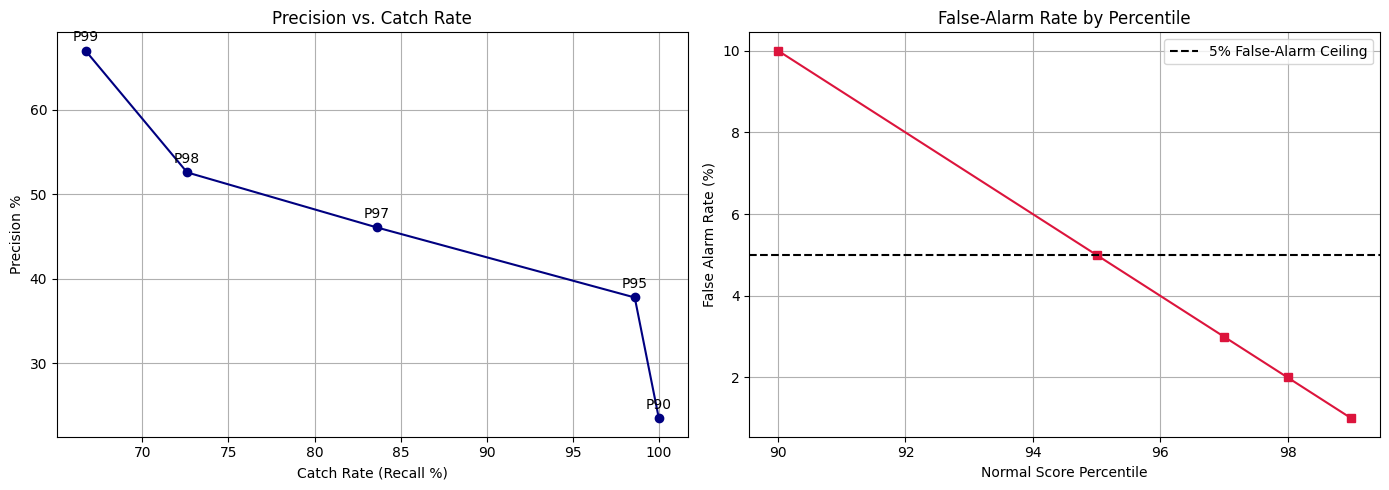

In [ ]:
# visualizing precision vs catch rate and false alarm rate
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Precision vs Catch Rate
raw_catch = [float(r["Catch Rate (Recall)"].replace('%','')) for r in results]
raw_prec = [float(r["Precision"].replace('%','')) for r in results]
axes[0].plot(raw_catch, raw_prec, marker='o', color='navy')
for i, r in enumerate(results):
    axes[0].annotate(f"P{r['Percentile']}", (raw_catch[i], raw_prec[i]), textcoords="offset points", xytext=(0, 7), ha='center')
axes[0].set_xlabel("Catch Rate (Recall %)")
axes[0].set_ylabel("Precision %")
axes[0].set_title("Precision vs. Catch Rate")
axes[0].grid(True)

# False Alarm Rate
raw_fa = [float(r["False-Alarm Rate"].replace('%','')) for r in results]
raw_p = [r["Percentile"] for r in results]
axes[1].plot(raw_p, raw_fa, marker='s', color='crimson')
axes[1].axhline(y=5, color='black', linestyle='--', label='5% False-Alarm Ceiling')
axes[1].set_xlabel("Normal Score Percentile")
axes[1].set_ylabel("False Alarm Rate (%)")
axes[1].set_title("False-Alarm Rate by Percentile")
axes[1].legend()
axes[1].grid(True)

plt.tight_layout()
plt.show()
